# Word-Level Nomenclator Separation

## Motivation

Notebook 30 tested the nomenclator hypothesis at the **glyph level**, separating
the 166 STA1 glyphs into letter-substitution vs code-word populations. The result
was negative: the "code-glyphs" were simply rare glyphs (freq ≤ 10, 0.1% of corpus).

However, historically accurate 15th-century nomenclators encoded at the **word level**:
certain *whole words* in the ciphertext represent concepts (names, places, frequent
nouns) rather than being composed of letter-substitution glyphs. These code-words
would be:

- **Internally irregular**: not following the onset–nucleus–coda (SilPart) pattern
- **Positionally anomalous**: using glyphs in positions where they don't usually appear
- **Transition-breaking**: low internal transition probabilities between consecutive glyphs

If the Voynich is a nomenclator, we should find a subpopulation of words that
violates the strong positional structure that SilPart captures so well.

## Method

1. Compute 7 structural features per **word type** (positional regularity, transition
   smoothness, glyph position-lock score, syllabic well-formedness)
2. Cluster word types with GMM (k=2): "regular" (enciphered) vs "irregular" (code-words)
3. Validate: do "irregular" words form a distinct population?
4. Attempt Neural v2 decipherment on "regular" words only
5. Compare with full-corpus baseline (68% n-gram from notebook 14)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from tqdm.notebook import tqdm

from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})
DEVICE = torch.device('cpu')
N_CPUS = os.cpu_count() or 4
N_WORKERS = min(N_CPUS - 1, 10)
print(f'Device: {DEVICE}, CPUs: {N_CPUS}, workers: {N_WORKERS}')

# ── Parser STA1 2.0 ─────────────────────────────────────────────────
def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens

def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras

STA_PATH = 'corpus/voynich_sta.txt'
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
glyph_freq = Counter(corpus_plano)
word_freq = Counter(tuple(w) for w in palabras)

print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} glyphs, {len(VOCAB)} glyph types')
print(f'Unique word types: {len(word_freq):,}')

Device: cpu, CPUs: 16, workers: 10
Voynich: 37,087 words, 157,254 glyphs, 166 glyph types
Unique word types: 10,127


In [2]:
# ── Glyph positional statistics ───────────────────────────────────────
# For each glyph, compute its preferred position(s) within words

onset_counts = Counter()   # word-initial
middle_counts = Counter()  # internal
coda_counts = Counter()    # word-final
total_counts = Counter()

for w in palabras:
    n = len(w)
    for i, g in enumerate(w):
        total_counts[g] += 1
        if n == 1:
            onset_counts[g] += 1
            coda_counts[g] += 1
        elif i == 0:
            onset_counts[g] += 1
        elif i == n - 1:
            coda_counts[g] += 1
        else:
            middle_counts[g] += 1

# Position probability vectors per glyph
glyph_pos_prob = {}
for g in VOCAB:
    t = total_counts[g]
    if t == 0:
        glyph_pos_prob[g] = np.array([1/3, 1/3, 1/3])
    else:
        glyph_pos_prob[g] = np.array([onset_counts[g]/t, middle_counts[g]/t, coda_counts[g]/t])

# Position-lock: dominant position fraction
glyph_pos_lock = {}
for g in VOCAB:
    glyph_pos_lock[g] = float(np.max(glyph_pos_prob[g]))

# Transition matrix (intra-word bigrams)
M_raw = np.zeros((len(VOCAB), len(VOCAB)))
g2i = {g: i for i, g in enumerate(VOCAB)}
for w in palabras:
    for j in range(len(w) - 1):
        M_raw[g2i[w[j]], g2i[w[j+1]]] += 1

row_sums = M_raw.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
M_prob = M_raw / row_sums

print(f'Glyph positional stats computed for {len(VOCAB)} glyphs')
print(f'Mean position-lock: {np.mean(list(glyph_pos_lock.values())):.3f}')
print(f'Transition matrix: {M_prob.shape}')

Glyph positional stats computed for 166 glyphs
Mean position-lock: 0.851
Transition matrix: (166, 166)


Word feature matrix: (10127, 8) (word types × features)

Feature statistics (raw):
        word_len    log_freq  mean_pos_lock  pos_consistency  mean_trans_prob  min_trans_prob  rare_glyph_frac  mean_glyph_pos_H
count  10127.000  10127.0000     10127.0000       10127.0000       10127.0000      10127.0000       10127.0000        10127.0000
mean       5.429      1.4114         0.7467           0.6234           0.2057          0.0486           0.0202            0.8397
std        1.772      0.9575         0.0700           0.1271           0.1076          0.0946           0.0855            0.1683
min        1.000      1.0000         0.4542           0.0042           0.0000          0.0000           0.0000            0.0000
25%        4.000      1.0000         0.7020           0.5513           0.1459          0.0064           0.0000            0.7266
50%        5.000      1.0000         0.7492           0.6313           0.1954          0.0170           0.0000            0.8367
75%        6.0

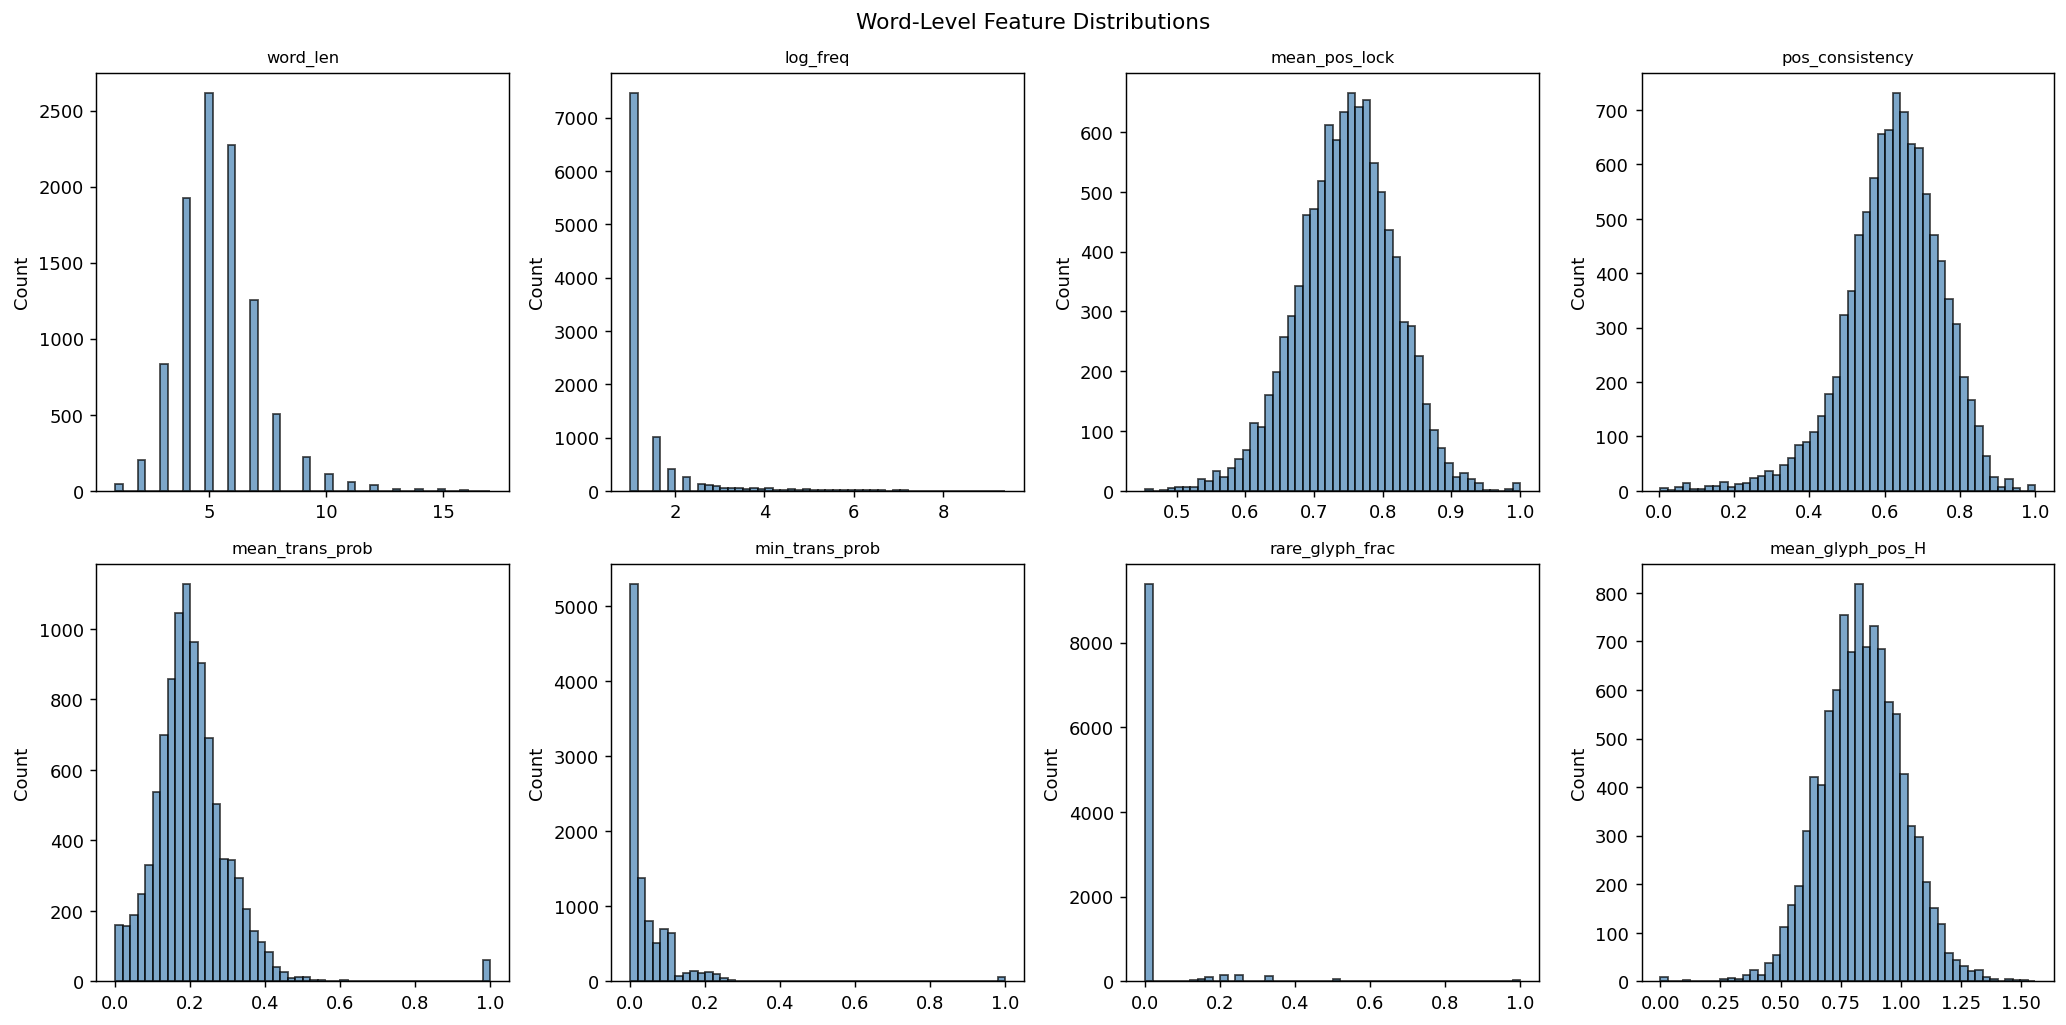

Saved: images/nomenclator_word_features.png


In [3]:
# ── Word-level features (7 per word type) ────────────────────────────

def compute_word_features(word_types, word_freq_map):
    features = {}

    for wt in word_types:
        w = list(wt)
        n = len(w)
        freq = word_freq_map[wt]

        # F1: Word length
        f1_length = n

        # F2: Log frequency
        f2_logfreq = math.log2(freq + 1)

        # F3: Mean position-lock score of constituent glyphs
        # High = glyphs are used in their "correct" positions
        f3_mean_pos_lock = np.mean([glyph_pos_lock.get(g, 0) for g in w])

        # F4: Positional consistency — are glyphs in their expected positions?
        # For each glyph, check if its actual position matches its dominant position
        pos_correct = 0
        for i, g in enumerate(w):
            probs = glyph_pos_prob.get(g, np.array([1/3, 1/3, 1/3]))
            if n == 1:
                actual_pos = 0  # onset
            elif i == 0:
                actual_pos = 0  # onset
            elif i == n - 1:
                actual_pos = 2  # coda
            else:
                actual_pos = 1  # middle
            pos_correct += probs[actual_pos]
        f4_pos_consistency = pos_correct / n

        # F5: Mean transition probability (smoothness)
        # High = glyph pairs are common (regular word)
        if n >= 2:
            trans_probs = []
            for j in range(n - 1):
                g1, g2 = w[j], w[j+1]
                if g1 in g2i and g2 in g2i:
                    trans_probs.append(M_prob[g2i[g1], g2i[g2]])
                else:
                    trans_probs.append(0.0)
            f5_mean_trans = np.mean(trans_probs)
            f5b_min_trans = np.min(trans_probs)
        else:
            f5_mean_trans = 1.0
            f5b_min_trans = 1.0

        # F6: Glyph uniqueness — what fraction of glyphs are rare (freq < 100)?
        f6_rare_frac = np.mean([1 if glyph_freq.get(g, 0) < 100 else 0 for g in w])

        # F7: Positional entropy of the word's glyph sequence
        # Low = glyphs are concentrated in few positions (regular)
        pos_entropies = []
        for g in w:
            probs = glyph_pos_prob.get(g, np.array([1/3, 1/3, 1/3]))
            probs_nz = probs[probs > 0]
            H = -np.sum(probs_nz * np.log2(probs_nz))
            pos_entropies.append(H)
        f7_mean_glyph_pos_H = np.mean(pos_entropies)

        features[wt] = [f1_length, f2_logfreq, f3_mean_pos_lock,
                         f4_pos_consistency, f5_mean_trans, f5b_min_trans,
                         f6_rare_frac, f7_mean_glyph_pos_H]

    return features

feature_names = ['word_len', 'log_freq', 'mean_pos_lock', 'pos_consistency',
                 'mean_trans_prob', 'min_trans_prob', 'rare_glyph_frac', 'mean_glyph_pos_H']

word_types = sorted(word_freq.keys())
word_features = compute_word_features(word_types, word_freq)

X_raw = np.array([word_features[wt] for wt in word_types])
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print(f'Word feature matrix: {X.shape} (word types × features)')
print(f'\nFeature statistics (raw):')
df_feat = pd.DataFrame(X_raw, columns=feature_names)
print(df_feat.describe().round(4).to_string())

# ── Feature distributions ──
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, (ax, fname) in enumerate(zip(axes.flat, feature_names)):
    ax.hist(X_raw[:, i], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    ax.set_title(fname, fontsize=9)
    ax.set_ylabel('Count')
plt.suptitle('Word-Level Feature Distributions', fontsize=12)
plt.tight_layout()
plt.savefig('images/nomenclator_word_features.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/nomenclator_word_features.png')

## Clustering Word Types

We cluster word types into 2 populations:
- **Regular** (enciphered text): high positional consistency, smooth transitions, common glyphs
- **Irregular** (code-words): anomalous structure, unusual glyph combinations

If the nomenclator hypothesis holds, the irregular population should be a meaningful
minority (10-30% of tokens), not just rare hapax legomena.

=== WORD-LEVEL CLUSTERING ===
GMM k=2:     silhouette=0.416, sizes=[ 990 9137]
K-Means k=2: silhouette=0.217, sizes=[5013 5114]
Agreement ARI: 0.002

BIC scan:
  k=1: BIC=192309.0
  k=2: BIC=49969.9
  k=3: BIC=-40200.9
  k=4: BIC=-51338.7
  k=5: BIC=-55200.5
  k=6: BIC=-62973.0 ← BEST

=== POPULATION ASSIGNMENT ===
Regular (enciphered): 990 types (9.8%), 18,519 tokens (49.9%)
Irregular (code-words): 9,137 types (90.2%), 18,568 tokens (50.1%)


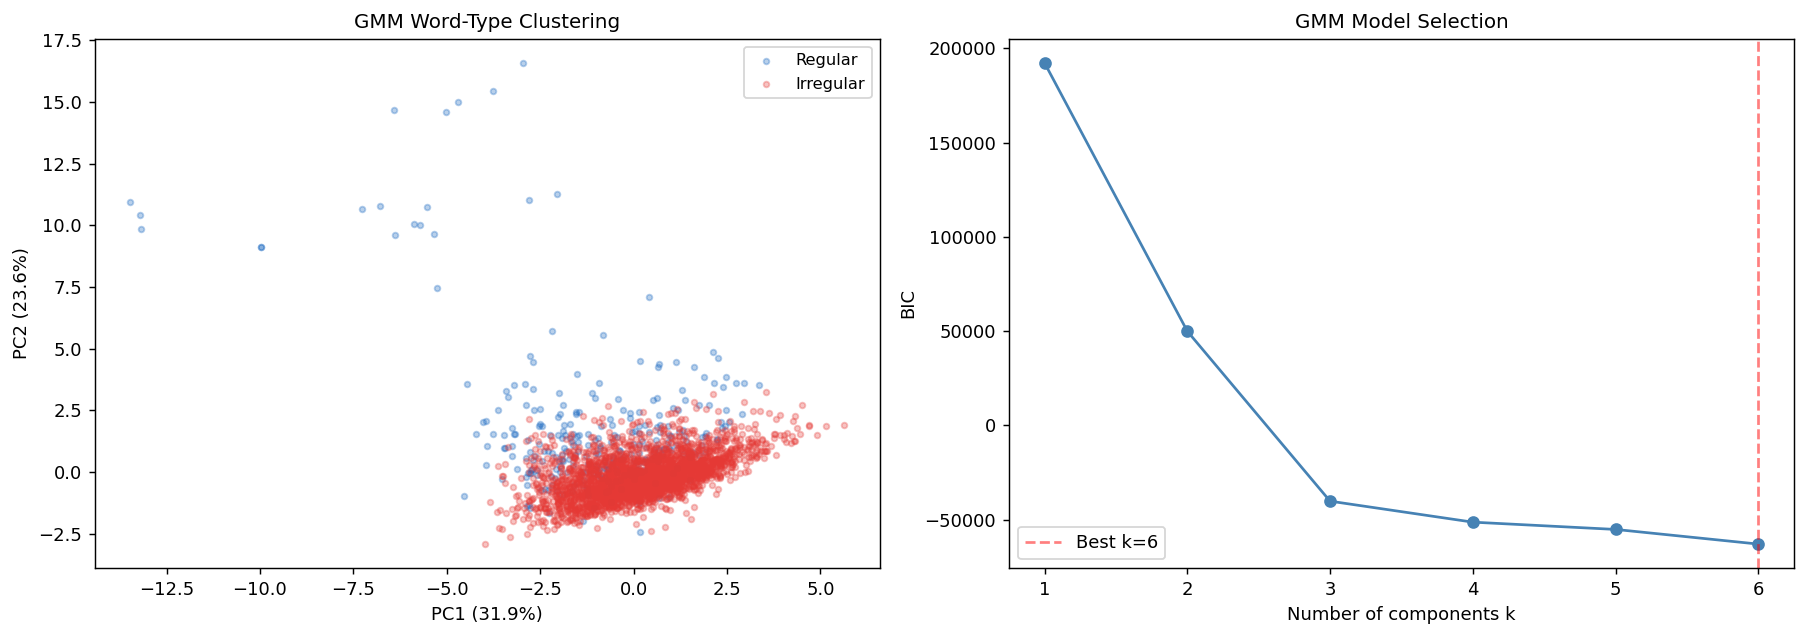

Saved: images/nomenclator_word_clustering.png


In [4]:
# ── Clustering word types ────────────────────────────────────────────
np.random.seed(42)

# GMM k=2
gmm2 = GaussianMixture(n_components=2, covariance_type='full',
                        n_init=10, random_state=42)
labels_gmm = gmm2.fit_predict(X)
probs_gmm = gmm2.predict_proba(X)

# K-Means k=2
km2 = KMeans(n_clusters=2, n_init=20, random_state=42)
labels_km = km2.fit_predict(X)

# Silhouette
sil_gmm = silhouette_score(X, labels_gmm)
sil_km = silhouette_score(X, labels_km)

# BIC scan
bic_scores = []
for k in range(1, 7):
    gmm_k = GaussianMixture(n_components=k, covariance_type='full',
                             n_init=10, random_state=42)
    gmm_k.fit(X)
    bic_scores.append((k, gmm_k.bic(X)))

best_bic_k = min(bic_scores, key=lambda x: x[1])[0]

# Agreement
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(labels_gmm, labels_km)

print('=== WORD-LEVEL CLUSTERING ===')
print(f'GMM k=2:     silhouette={sil_gmm:.3f}, sizes={np.bincount(labels_gmm)}')
print(f'K-Means k=2: silhouette={sil_km:.3f}, sizes={np.bincount(labels_km)}')
print(f'Agreement ARI: {ari:.3f}')

print(f'\nBIC scan:')
for k, bic in bic_scores:
    marker = ' ← BEST' if k == best_bic_k else ''
    print(f'  k={k}: BIC={bic:.1f}{marker}')

# ── Identify regular vs irregular cluster ──
# Regular cluster = higher mean pos_consistency (feature 3)
cluster_means = []
for lab in range(2):
    mask = labels_gmm == lab
    mean_pos_cons = X_raw[mask, 3].mean()  # pos_consistency
    cluster_means.append(mean_pos_cons)

regular_label = np.argmax(cluster_means)
irregular_label = 1 - regular_label

n_regular = np.sum(labels_gmm == regular_label)
n_irregular = np.sum(labels_gmm == irregular_label)

# Token counts (frequency-weighted)
regular_tokens = sum(word_freq[word_types[i]] for i in range(len(word_types))
                     if labels_gmm[i] == regular_label)
irregular_tokens = sum(word_freq[word_types[i]] for i in range(len(word_types))
                       if labels_gmm[i] == irregular_label)
total_tokens = regular_tokens + irregular_tokens

print(f'\n=== POPULATION ASSIGNMENT ===')
print(f'Regular (enciphered): {n_regular:,} types ({100*n_regular/len(word_types):.1f}%), '
      f'{regular_tokens:,} tokens ({100*regular_tokens/total_tokens:.1f}%)')
print(f'Irregular (code-words): {n_irregular:,} types ({100*n_irregular/len(word_types):.1f}%), '
      f'{irregular_tokens:,} tokens ({100*irregular_tokens/total_tokens:.1f}%)')

# ── PCA visualization ──
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter (subsample for clarity)
rng_viz = np.random.default_rng(42)
viz_idx = rng_viz.choice(len(word_types), size=min(3000, len(word_types)), replace=False)

for lab, color, name in [(regular_label, '#1565C0', 'Regular'),
                          (irregular_label, '#E53935', 'Irregular')]:
    mask = np.array([labels_gmm[i] == lab for i in viz_idx])
    axes[0].scatter(X_pca[viz_idx[mask], 0], X_pca[viz_idx[mask], 1],
                   c=color, alpha=0.3, s=10, label=f'{name}')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_title('GMM Word-Type Clustering')
axes[0].legend(fontsize=9)

# BIC
ks = [k for k, _ in bic_scores]
bics = [b for _, b in bic_scores]
axes[1].plot(ks, bics, '-o', color='steelblue')
axes[1].set_xlabel('Number of components k')
axes[1].set_ylabel('BIC')
axes[1].set_title('GMM Model Selection')
axes[1].axvline(best_bic_k, ls='--', color='red', alpha=0.5, label=f'Best k={best_bic_k}')
axes[1].legend()

plt.tight_layout()
plt.savefig('images/nomenclator_word_clustering.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/nomenclator_word_clustering.png')

=== FEATURE COMPARISON: Regular vs Irregular ===
           Feature  Regular μ   Irreg. μ        Δ        t
          word_len     4.2939     5.5519  -1.2580   -19.14 ***
          log_freq     2.1278     1.3338  +0.7941    12.08 ***
     mean_pos_lock     0.7587     0.7454  +0.0132     4.40 ***
   pos_consistency     0.6377     0.6219  +0.0158     2.83 **
   mean_trans_prob     0.2863     0.1970  +0.0893    12.64 ***
    min_trans_prob     0.1244     0.0403  +0.0841    10.52 ***
   rare_glyph_frac     0.2066     0.0000  +0.2066    34.14 ***
  mean_glyph_pos_H     0.8071     0.8432  -0.0361    -4.82 ***

=== CLUSTER DIAGNOSTICS ===
Regular words:   mean freq=18.7, median=1, max=665
Irregular words: mean freq=2.0, median=1, max=30

Hapax (freq=1): regular 695/990 (70.2%), irregular 6764/9137 (74.0%)

Word length: regular 4.29±1.99, irregular 5.55±1.70

=== NOMENCLATOR PLAUSIBILITY (WORD-LEVEL) ===
                    Check     Result Detail
        Code-word token %       FAIL 50.1% (ex

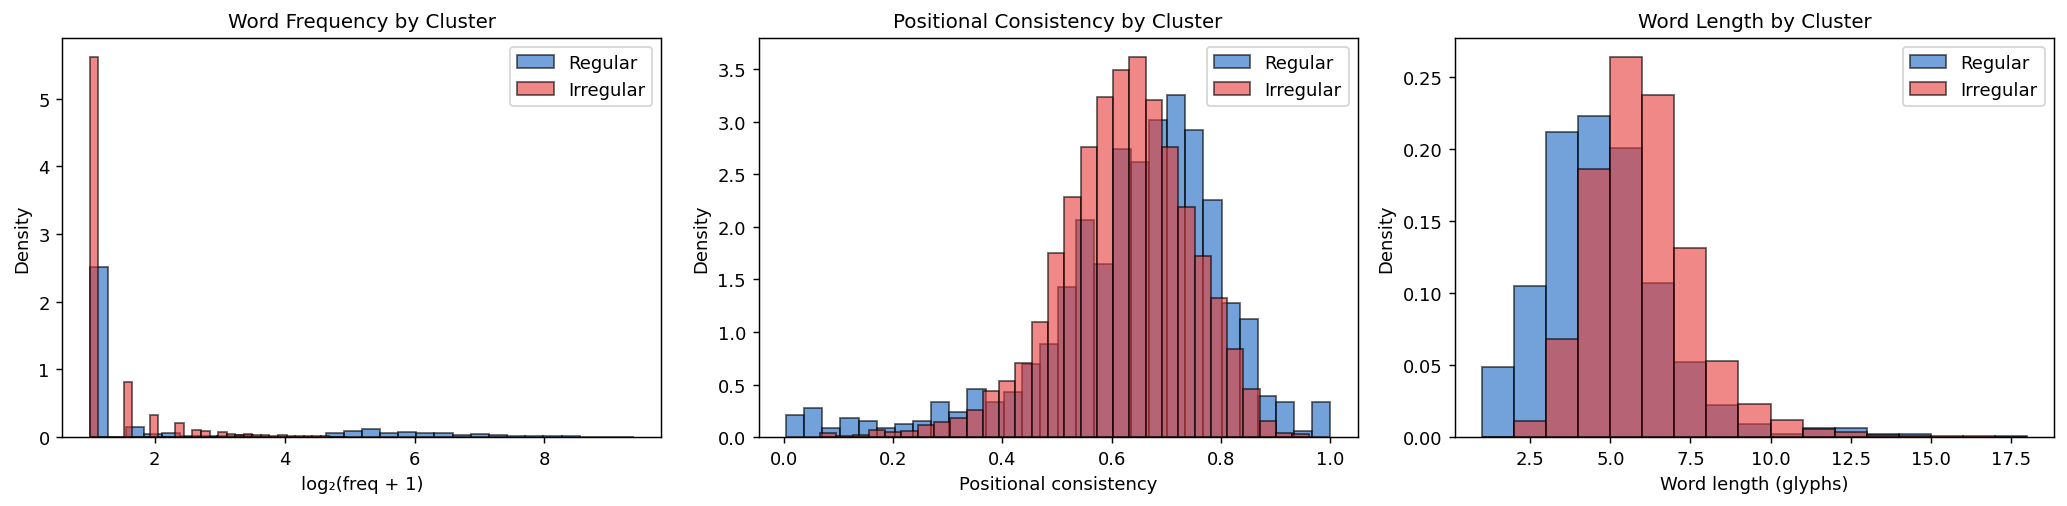

Saved: images/nomenclator_word_populations.png


In [5]:
# ── Feature comparison ────────────────────────────────────────────────
from scipy.stats import ttest_ind

print('=== FEATURE COMPARISON: Regular vs Irregular ===')
print(f'{"Feature":>18} {"Regular μ":>10} {"Irreg. μ":>10} {"Δ":>8} {"t":>8}')

for fi, fname in enumerate(feature_names):
    vals_reg = X_raw[labels_gmm == regular_label, fi]
    vals_irr = X_raw[labels_gmm == irregular_label, fi]
    t_stat, p_val = ttest_ind(vals_reg, vals_irr, equal_var=False)
    delta = vals_reg.mean() - vals_irr.mean()
    sig = '***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else ''
    print(f'{fname:>18} {vals_reg.mean():10.4f} {vals_irr.mean():10.4f} '
          f'{delta:+8.4f} {t_stat:8.2f} {sig}')

# ── Key diagnostic: what distinguishes the clusters? ──
print(f'\n=== CLUSTER DIAGNOSTICS ===')

# Frequency distribution
reg_freqs = [word_freq[word_types[i]] for i in range(len(word_types))
             if labels_gmm[i] == regular_label]
irr_freqs = [word_freq[word_types[i]] for i in range(len(word_types))
             if labels_gmm[i] == irregular_label]

print(f'Regular words:   mean freq={np.mean(reg_freqs):.1f}, median={np.median(reg_freqs):.0f}, '
      f'max={np.max(reg_freqs)}')
print(f'Irregular words: mean freq={np.mean(irr_freqs):.1f}, median={np.median(irr_freqs):.0f}, '
      f'max={np.max(irr_freqs)}')

# Hapax ratio
reg_hapax = sum(1 for f in reg_freqs if f == 1)
irr_hapax = sum(1 for f in irr_freqs if f == 1)
print(f'\nHapax (freq=1): regular {reg_hapax}/{len(reg_freqs)} ({100*reg_hapax/max(len(reg_freqs),1):.1f}%), '
      f'irregular {irr_hapax}/{len(irr_freqs)} ({100*irr_hapax/max(len(irr_freqs),1):.1f}%)')

# Word length distribution
reg_lens = [len(word_types[i]) for i in range(len(word_types)) if labels_gmm[i] == regular_label]
irr_lens = [len(word_types[i]) for i in range(len(word_types)) if labels_gmm[i] == irregular_label]
print(f'\nWord length: regular {np.mean(reg_lens):.2f}±{np.std(reg_lens):.2f}, '
      f'irregular {np.mean(irr_lens):.2f}±{np.std(irr_lens):.2f}')

# ── Nomenclator plausibility checks ──
print(f'\n=== NOMENCLATOR PLAUSIBILITY (WORD-LEVEL) ===')
checks = []

# Check 1: irregular tokens 10-30%?
irr_pct = 100 * irregular_tokens / total_tokens
if 10 <= irr_pct <= 40:
    checks.append(('Code-word token %', 'PASS', f'{irr_pct:.1f}% (expected 10-40%)'))
elif 5 <= irr_pct <= 50:
    checks.append(('Code-word token %', 'MARGINAL', f'{irr_pct:.1f}%'))
else:
    checks.append(('Code-word token %', 'FAIL', f'{irr_pct:.1f}% (expected 10-40%)'))

# Check 2: silhouette > 0.2
if sil_gmm > 0.2:
    checks.append(('Silhouette', 'PASS', f'{sil_gmm:.3f}'))
elif sil_gmm > 0.1:
    checks.append(('Silhouette', 'MARGINAL', f'{sil_gmm:.3f}'))
else:
    checks.append(('Silhouette', 'FAIL', f'{sil_gmm:.3f}'))

# Check 3: BIC prefers k=2
bic_dict = dict(bic_scores)
if bic_dict.get(2, 0) < bic_dict.get(1, 0):
    checks.append(('BIC k=2 vs k=1', 'PASS', f'BIC(2)={bic_dict[2]:.0f} < BIC(1)={bic_dict[1]:.0f}'))
else:
    checks.append(('BIC k=2 vs k=1', 'FAIL', f'k=2 not preferred'))

# Check 4: irregular words have DIFFERENT structure (not just rare)
# If irregular words are just hapax, this isn't nomenclator — just Zipf tail
if irr_pct > 5 and np.mean(irr_freqs) > 2:
    checks.append(('Not just hapax', 'PASS', f'mean freq={np.mean(irr_freqs):.1f}'))
elif np.mean(irr_freqs) > 1.5:
    checks.append(('Not just hapax', 'MARGINAL', f'mean freq={np.mean(irr_freqs):.1f}'))
else:
    checks.append(('Not just hapax', 'FAIL', f'mean freq={np.mean(irr_freqs):.1f} (just rare words)'))

# Check 5: pos_consistency significantly different
t_pc, p_pc = ttest_ind(
    X_raw[labels_gmm == regular_label, 3],
    X_raw[labels_gmm == irregular_label, 3], equal_var=False)
if p_pc < 0.001 and abs(t_pc) > 5:
    checks.append(('Structural difference', 'PASS', f't={t_pc:.1f}, p={p_pc:.2e}'))
elif p_pc < 0.05:
    checks.append(('Structural difference', 'MARGINAL', f't={t_pc:.1f}, p={p_pc:.2e}'))
else:
    checks.append(('Structural difference', 'FAIL', f't={t_pc:.1f}, p={p_pc:.2e}'))

n_pass = sum(1 for _, r, _ in checks if r == 'PASS')
n_marg = sum(1 for _, r, _ in checks if r == 'MARGINAL')
n_fail = sum(1 for _, r, _ in checks if r == 'FAIL')

print(f'{"Check":>25} {"Result":>10} {"Detail"}')
for name, result, detail in checks:
    print(f'{name:>25} {result:>10} {detail}')
print(f'\nPlausibility scorecard: {n_pass}+ / {n_marg}± / {n_fail}−')

# ── Visualization ──
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Frequency distribution
for lab, color, name in [(regular_label, '#1565C0', 'Regular'),
                          (irregular_label, '#E53935', 'Irregular')]:
    freqs = [word_freq[word_types[i]] for i in range(len(word_types)) if labels_gmm[i] == lab]
    axes[0].hist(np.log2(np.array(freqs) + 1), bins=30, alpha=0.6, color=color,
                 edgecolor='black', label=name, density=True)
axes[0].set_xlabel('log₂(freq + 1)')
axes[0].set_ylabel('Density')
axes[0].set_title('Word Frequency by Cluster')
axes[0].legend()

# Position consistency
for lab, color, name in [(regular_label, '#1565C0', 'Regular'),
                          (irregular_label, '#E53935', 'Irregular')]:
    vals = X_raw[labels_gmm == lab, 3]
    axes[1].hist(vals, bins=30, alpha=0.6, color=color, edgecolor='black',
                 label=name, density=True)
axes[1].set_xlabel('Positional consistency')
axes[1].set_ylabel('Density')
axes[1].set_title('Positional Consistency by Cluster')
axes[1].legend()

# Word length
for lab, color, name in [(regular_label, '#1565C0', 'Regular'),
                          (irregular_label, '#E53935', 'Irregular')]:
    lens = [len(word_types[i]) for i in range(len(word_types)) if labels_gmm[i] == lab]
    axes[2].hist(lens, bins=range(1, max(lens)+2), alpha=0.6, color=color,
                 edgecolor='black', label=name, density=True)
axes[2].set_xlabel('Word length (glyphs)')
axes[2].set_ylabel('Density')
axes[2].set_title('Word Length by Cluster')
axes[2].legend()

plt.tight_layout()
plt.savefig('images/nomenclator_word_populations.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/nomenclator_word_populations.png')

## Decipherment: Regular Words Only

We test whether restricting to structurally regular words (the "enciphered" subset)
improves decipherment over the full corpus.

In [6]:
# ── Hebrew corpus + LSTM ──────────────────────────────────────────────

def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Descargando {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Total: {len(todas_palabras):,} words')
    return todas_palabras

print('Downloading Hebrew corpus...')
hebrew_words_full = descargar_hebreo()
rng_sub = np.random.default_rng(42)
if len(hebrew_words_full) > N_VOYNICH:
    idx = rng_sub.choice(len(hebrew_words_full), size=N_VOYNICH, replace=False)
    hebrew_words = [hebrew_words_full[i] for i in sorted(idx)]
else:
    hebrew_words = hebrew_words_full
print(f'Subsampled: {len(hebrew_words):,} words')

HEBREW_VOWELS = set('\u05D0\u05D4\u05D5\u05D9')
target_chars = sorted(set(c for w in hebrew_words for c in w))
char_role = {c: 'V' if c in HEBREW_VOWELS else 'C' for c in target_chars}

# ── LSTM ──
class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos, eos = char2idx['<w>'], char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                self.samples.append((indices[i-2:i], indices[i]))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        ctx, tgt = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(tgt, dtype=torch.long)

class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        return self.fc(self.dropout(out)), hidden

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos, eos = self.char2idx['<w>'], self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx, all_tgt = [], []
            word_boundaries = [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))
            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(palabras))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            CHUNK = 16384
            all_lps = []
            for start in range(0, n_total, CHUNK):
                end = min(start + CHUNK, n_total)
                logits, _ = self.forward(ctx_t[start:end])
                logits_last = logits[:, -1, :] / temperature
                log_p = torch.log_softmax(logits_last, dim=-1)
                all_lps.append(log_p.gather(1, tgt_t[start:end].unsqueeze(1)).squeeze(1))
            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)
            word_lps = np.zeros(len(palabras))
            for wi in range(len(palabras)):
                s, e = word_boundaries[wi], word_boundaries[wi + 1]
                if s < e:
                    word_lps[wi] = all_lps[s:e].sum()
            return word_lps

all_chars_heb = sorted(set(c for w in hebrew_words for c in w))
special_tokens = ['<pad>', '<w>', '</w>', '<unk>']
char_vocab = special_tokens + all_chars_heb
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}

rng_split = np.random.default_rng(42)
n_val = int(0.2 * len(hebrew_words))
perm = rng_split.permutation(len(hebrew_words))
val_idx = set(perm[:n_val])
train_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i not in val_idx]
val_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i in val_idx]

train_loader = DataLoader(CharDataset(train_words, char2idx), batch_size=256, shuffle=True)
val_loader = DataLoader(CharDataset(val_words, char2idx), batch_size=256, shuffle=False)

neural_lm = NeuralCharLM(len(char_vocab)).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char

optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

best_val_loss, patience_counter, best_state_dict = float('inf'), 0, None
train_losses, val_losses = [], []
print(f'Training Neural LM (30 epochs, patience=5)...')
t0 = time.time()

for epoch in range(30):
    neural_lm.train()
    el, nb = 0.0, 0
    for ctx_b, tgt_b in train_loader:
        ctx_b, tgt_b = ctx_b.to(DEVICE), tgt_b.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = neural_lm(ctx_b)
        loss = criterion(logits[:, -1, :], tgt_b)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        el += loss.item(); nb += 1
    train_losses.append(el / max(nb, 1))
    neural_lm.eval()
    vl, nvb = 0.0, 0
    with torch.no_grad():
        for ctx_b, tgt_b in val_loader:
            ctx_b, tgt_b = ctx_b.to(DEVICE), tgt_b.to(DEVICE)
            logits, _ = neural_lm(ctx_b)
            vl += criterion(logits[:, -1, :], tgt_b).item(); nvb += 1
    val_loss = vl / max(nvb, 1)
    val_losses.append(val_loss)
    scheduler.step()
    if (epoch + 1) % 10 == 0:
        print(f'  Epoch {epoch+1}: train={train_losses[-1]:.4f}, val={val_loss:.4f}')
    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss; patience_counter = 0
        best_state_dict = copy.deepcopy(neural_lm.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= 5:
            print(f'  Early stopping at epoch {epoch+1}'); break

neural_lm.load_state_dict(best_state_dict)
print(f'Done in {time.time()-t0:.1f}s, best val_loss={best_val_loss:.4f}')

  Descargando Genesis...
  Descargando Exodus...
  Descargando Leviticus...
  Descargando Numbers...
  Descargando Deuteronomy...
  Total: 80,051 words
Subsampled: 37,087 words
Training Neural LM (30 epochs, patience=5)...
  Epoch 10: train=2.0333, val=2.0157
  Epoch 20: train=2.0101, val=2.0057
  Epoch 30: train=2.0003, val=2.0037
Done in 78.5s, best val_loss=2.0037


In [7]:
# ── EM infrastructure ─────────────────────────────────────────────────

HEBREW_CONSONANTS_SET = set('\u05D1\u05D2\u05D3\u05D4\u05D5\u05D6\u05D7\u05D8\u05D9\u05DB\u05DC\u05DE\u05E0\u05E1\u05E2\u05E4\u05E6\u05E7\u05E8\u05E9\u05EA') | set('\u05DA\u05DD\u05DF\u05E3\u05E5')
HEBREW_MATRES = set('\u05D0\u05D5\u05D9')
HEBREW_ROOTS = {
    '\u05D0\u05DE\u05E8', '\u05D3\u05D1\u05E8', '\u05D4\u05D9\u05D4', '\u05D1\u05D5\u05D0', '\u05E2\u05E9\u05D4',
    '\u05E0\u05EA\u05DF', '\u05D9\u05D3\u05E2', '\u05D4\u05DC\u05DA', '\u05E8\u05D0\u05D4', '\u05E9\u05DE\u05E2',
    '\u05D0\u05DB\u05DC', '\u05DC\u05E7\u05D7', '\u05D9\u05E9\u05D1', '\u05E7\u05E8\u05D0', '\u05E9\u05DC\u05D7',
    '\u05E2\u05DC\u05D4', '\u05DE\u05D5\u05EA', '\u05E9\u05D5\u05D1', '\u05D1\u05E8\u05DA', '\u05D9\u05E6\u05D0',
    '\u05E2\u05D1\u05E8', '\u05E9\u05DE\u05E8', '\u05DB\u05EA\u05D1', '\u05E0\u05E9\u05D0', '\u05D6\u05DB\u05E8',
    '\u05D9\u05DC\u05D3', '\u05E2\u05DE\u05D3', '\u05E4\u05E0\u05D4', '\u05D1\u05E0\u05D4', '\u05E0\u05E4\u05DC',
    '\u05E9\u05D9\u05DD', '\u05D7\u05D9\u05D4', '\u05D2\u05D3\u05DC', '\u05E7\u05D5\u05DD', '\u05DE\u05DC\u05D0',
    '\u05DE\u05E6\u05D0', '\u05E9\u05E4\u05D8', '\u05D0\u05D4\u05D1', '\u05D9\u05E8\u05D3', '\u05E0\u05D2\u05D3',
    '\u05D9\u05E1\u05E3', '\u05D7\u05D8\u05D0', '\u05E7\u05D3\u05E9', '\u05DB\u05D4\u05DF', '\u05E6\u05D5\u05D4',
    '\u05D1\u05E8\u05D0', '\u05D2\u05DC\u05D4', '\u05D6\u05D1\u05D7', '\u05D8\u05D4\u05E8', '\u05D8\u05DE\u05D0',
    '\u05D0\u05E8\u05E5', '\u05D1\u05D9\u05EA', '\u05E9\u05E0\u05D4', '\u05D9\u05D5\u05DD', '\u05DE\u05D9\u05DD',
    '\u05E9\u05DE\u05E9', '\u05DC\u05D9\u05DC', '\u05D0\u05D1\u05DF', '\u05E2\u05D9\u05E8', '\u05D3\u05E8\u05DA',
    '\u05DE\u05DC\u05DA', '\u05DB\u05E1\u05E3', '\u05D6\u05D4\u05D1', '\u05D3\u05DE\u05DD', '\u05E8\u05D5\u05D7',
    '\u05E0\u05E4\u05E9', '\u05DC\u05D7\u05DD', '\u05E2\u05D9\u05DF', '\u05D9\u05D3\u05D3', '\u05E9\u05D3\u05D4',
    '\u05E2\u05D1\u05D3', '\u05DB\u05DC\u05D9', '\u05E4\u05E8\u05D9', '\u05D7\u05D3\u05E9', '\u05E1\u05E4\u05E8',
    '\u05E2\u05E6\u05DD', '\u05D1\u05E9\u05E8', '\u05D0\u05D3\u05DD', '\u05E0\u05D4\u05E8', '\u05D2\u05D1\u05E8',
    '\u05E8\u05D2\u05DC', '\u05E8\u05D0\u05E9', '\u05D7\u05D6\u05E7', '\u05E8\u05D1\u05D1', '\u05E7\u05D8\u05DF',
    '\u05D8\u05D5\u05D1', '\u05E8\u05E2\u05E2', '\u05D7\u05DB\u05DD', '\u05E6\u05D3\u05E7', '\u05E8\u05D7\u05DD',
    '\u05DB\u05D5\u05DC', '\u05D1\u05E7\u05E8', '\u05E6\u05D0\u05DF', '\u05E2\u05D5\u05E3', '\u05D3\u05D2\u05D2',
    '\u05E9\u05DE\u05DF', '\u05D9\u05D9\u05DF', '\u05E1\u05D5\u05E1', '\u05D2\u05DE\u05DC', '\u05D7\u05DE\u05E8',
}

def extract_skeleton_deterministic(mapped_word):
    return ''.join(c for c in mapped_word if c in HEBREW_CONSONANTS_SET and c not in HEBREW_MATRES)

def count_roots_quick(mapping_dict, palabras_sample, top_n=200):
    wf = Counter(tuple(w) for w in palabras_sample)
    roots_matched = set()
    for word_tuple, freq in wf.most_common(top_n):
        skel = extract_skeleton_deterministic([mapping_dict.get(g, '?') for g in word_tuple])
        if len(skel) >= 3:
            for i in range(len(skel) - 2):
                tri = skel[i:i+3]
                if tri in HEBREW_ROOTS:
                    roots_matched.add(tri)
    return roots_matched, len(roots_matched)

class GlyphMappingState:
    def __init__(self, voynich_glyphs, target_chars_list, glyph_role_map=None, char_role_map=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars_list)
        self.glyph_role = glyph_role_map or {}
        self.char_role = char_role_map or {}
        self.mapping = {}
    def set_mapping(self, m):
        self.mapping = dict(m)
    def propose_change_tracked(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars, self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        g = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(g) in ('C', 'V'):
            cands = [c for c in self.target_chars if self.char_role.get(c) == self.glyph_role[g]]
            if not cands: cands = self.target_chars
        else:
            cands = self.target_chars
        new.mapping[g] = rng.choice(cands)
        return new, g
    def apply_word(self, w):
        return [self.mapping.get(g, '?') for g in w]

def build_glyph_word_index(words):
    idx = defaultdict(list)
    for wi, word in enumerate(words):
        for g in set(word):
            idx[g].append(wi)
    return idx

def score_total(state, words_sample, glyph_role_map, char_role_map, word_lps=None):
    if word_lps is None:
        mapped = [state.apply_word(w) for w in words_sample]
        word_lps = neural_lm.batch_log_prob(mapped, 2.0)
    s_lm = float(np.mean(word_lps))
    n_ok = sum(1 for g, c in state.mapping.items()
               if glyph_role_map.get(g, '?') == char_role_map.get(c, '?')
               and glyph_role_map.get(g) != '?')
    n_t = sum(1 for g in state.mapping if glyph_role_map.get(g) != '?')
    s_pos = n_ok / max(n_t, 1)
    K = len(set(state.mapping.values()))
    s_card = 0.0 if K >= 23 else -((23 - K) ** 2)
    cc = Counter(state.mapping.values())
    total_c = sum(cc.values())
    probs = np.array([c/total_c for c in cc.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(cc)) if len(cc) > 1 else 1
    s_ent = H / H_max if H_max > 0 else 0
    return 2.0 * s_lm + 0.5 * s_pos + 0.5 * s_card + 0.3 * s_ent, word_lps

def score_incremental(proposal, changed, words_sample, glyph_role_map, char_role_map,
                      glyph_word_idx, prev_wlps):
    new_wlps = prev_wlps.copy()
    affected = glyph_word_idx.get(changed, [])
    if affected:
        aff_mapped = [proposal.apply_word(words_sample[wi]) for wi in affected]
        new_lps = neural_lm.batch_log_prob(aff_mapped, 2.0)
        for j, wi in enumerate(affected):
            new_wlps[wi] = new_lps[j]
    return score_total(proposal, words_sample, glyph_role_map, char_role_map, new_wlps)

# ── Build glyph roles ──
def build_glyph_role(palabras_in, vocab_in):
    oc, mc, cc = Counter(), Counter(), Counter()
    for w in palabras_in:
        for i, g in enumerate(w):
            if i == 0: oc[g] += 1
            elif i == len(w) - 1: cc[g] += 1
            else: mc[g] += 1
    roles = {}
    for g in vocab_in:
        t = oc[g] + mc[g] + cc[g]
        roles[g] = 'V' if t >= 5 and mc[g]/t > 0.40 else 'C' if t >= 5 else '?'
    return roles

# ── Prepare two word sets ──
regular_set = set(word_types[i] for i in range(len(word_types)) if labels_gmm[i] == regular_label)
palabras_regular = [w for w in palabras if tuple(w) in regular_set]

VOCAB_FULL = VOCAB
VOCAB_REG = sorted(set(g for w in palabras_regular for g in w))
glyph_role_full = build_glyph_role(palabras, VOCAB_FULL)
glyph_role_reg = build_glyph_role(palabras_regular, VOCAB_REG)

print(f'Full:    {len(palabras):,} words, {len(VOCAB_FULL)} glyphs')
print(f'Regular: {len(palabras_regular):,} words, {len(VOCAB_REG)} glyphs')

# ── Parallel EM worker ──
def run_single_seed(args):
    seed_id, cond_name, palabras_em, vocab_em, glyph_role_em = args
    torch.set_num_threads(1)

    rng = np.random.default_rng(42 + seed_id * 1000 + hash(cond_name) % 10000)
    sample_idx = rng.choice(len(palabras_em), size=min(1500, len(palabras_em)), replace=False)
    words_sample = [palabras_em[i] for i in sample_idx]
    gwi = build_glyph_word_index(words_sample)

    state = GlyphMappingState(vocab_em, target_chars, glyph_role_em, char_role)
    # Init: frequency-based + 50% random
    gf = Counter(g for p in palabras_em for g in p)
    cf = Counter(c for w in hebrew_words for c in w)
    init_map = {}
    for role in ('C', 'V', '?'):
        gs = sorted([g for g in vocab_em if glyph_role_em.get(g, '?') == role],
                    key=lambda g: gf.get(g, 0), reverse=True)
        cs = sorted([c for c in target_chars if char_role.get(c) == role],
                    key=lambda c: cf.get(c, 0), reverse=True) if role != '?' else \
             sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        if not cs: cs = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(gs):
            init_map[g] = cs[i % len(cs)]
    for g in vocab_em:
        if rng.random() < 0.5:
            r = glyph_role_em.get(g, '?')
            cands = [c for c in target_chars if char_role.get(c) == r] if r in ('C','V') else target_chars
            init_map[g] = rng.choice(cands if cands else target_chars)
    state.set_mapping(init_map)

    best_score, best_wlps = score_total(state, words_sample, glyph_role_em, char_role)
    best_map = dict(state.mapping)
    no_improve = 0
    for iteration in range(1500):
        accepted = 0
        for _ in range(100):
            prop, ch = state.propose_change_tracked(rng, constrained=True)
            ns, nwlps = score_incremental(prop, ch, words_sample, glyph_role_em, char_role, gwi, best_wlps)
            if ns > best_score:
                state = prop; best_score = ns; best_wlps = nwlps
                best_map = dict(state.mapping); accepted += 1; no_improve = 0
        if accepted == 0: no_improve += 1
        if no_improve >= 80: break

    roots, _ = count_roots_quick(best_map, palabras_em)
    return {'seed': seed_id, 'cond': cond_name, 'score': best_score,
            'mapping': best_map, 'roots': roots, 'n_roots': len(roots),
            'iterations': iteration + 1, 'K': len(set(best_map.values()))}

# ── Run parallel ──
N_SEEDS = 10
all_args = []
for s in range(N_SEEDS):
    all_args.append((s, 'FULL', palabras, VOCAB_FULL, glyph_role_full))
    all_args.append((s, 'REGULAR', palabras_regular, VOCAB_REG, glyph_role_reg))

print(f'\nRunning {len(all_args)} EM jobs on {N_WORKERS} workers...')
t0 = time.time()
ctx = mp.get_context('fork')
with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as pool:
    all_results = list(pool.map(run_single_seed, all_args, chunksize=1))
print(f'Done in {time.time()-t0:.0f}s')

results_full = [r for r in all_results if r['cond'] == 'FULL']
results_reg = [r for r in all_results if r['cond'] == 'REGULAR']

print(f'\n=== FULL ===')
for r in results_full:
    print(f"  Seed {r['seed']}: score={r['score']:.2f}, roots={r['n_roots']}, K={r['K']}")
print(f'\n=== REGULAR ONLY ===')
for r in results_reg:
    print(f"  Seed {r['seed']}: score={r['score']:.2f}, roots={r['n_roots']}, K={r['K']}")

Full:    37,087 words, 166 glyphs
Regular: 18,519 words, 166 glyphs

Running 20 EM jobs on 10 workers...
Done in 178s

=== FULL ===
  Seed 0: score=-34.25, roots=0, K=27
  Seed 1: score=-34.74, roots=0, K=27
  Seed 2: score=-34.80, roots=0, K=27
  Seed 3: score=-35.75, roots=0, K=27
  Seed 4: score=-34.12, roots=0, K=27
  Seed 5: score=-34.37, roots=0, K=27
  Seed 6: score=-38.41, roots=0, K=27
  Seed 7: score=-34.19, roots=0, K=27
  Seed 8: score=-34.32, roots=0, K=27
  Seed 9: score=-34.78, roots=0, K=27

=== REGULAR ONLY ===
  Seed 0: score=-27.19, roots=0, K=27
  Seed 1: score=-27.19, roots=0, K=27
  Seed 2: score=-26.81, roots=0, K=27
  Seed 3: score=-29.19, roots=0, K=27
  Seed 4: score=-26.85, roots=0, K=27
  Seed 5: score=-26.90, roots=0, K=27
  Seed 6: score=-26.91, roots=0, K=27
  Seed 7: score=-26.82, roots=0, K=27
  Seed 8: score=-27.47, roots=0, K=27
  Seed 9: score=-27.00, roots=0, K=27


Computing n-gram percentiles...
Full:    100.0%
Regular: 100.0%

COMPARISON TABLE
              Metric         Full      Regular       v2 ref
        |Σ| (glyphs)          166          166          166
               Words       37,087       18,519       37,087
       EM best score       -34.12       -26.81       -36.34
            EM roots            0            0            3
         N-gram %ile         100%         100%          68%
               K_eff           27           27           25


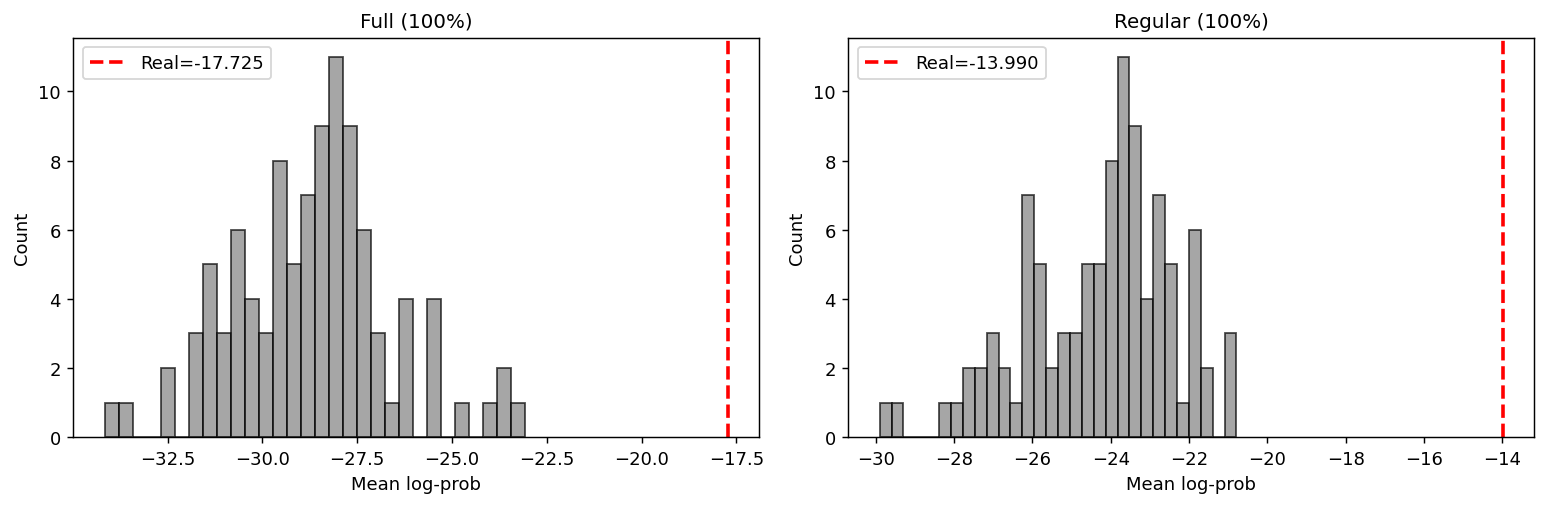

In [8]:
# ── N-gram percentilee ─────────────────────────────────────────────────
def ngram_percentile(mapping_dict, palabras_test, n_shuffles=100, sample_n=1500):
    rng_ng = np.random.default_rng(42)
    si = rng_ng.choice(len(palabras_test), size=min(sample_n, len(palabras_test)), replace=False)
    ws = [palabras_test[i] for i in si]
    vocab_used = sorted(set(g for w in ws for g in w))

    mapped_real = [[mapping_dict.get(g, '?') for g in w] for w in ws]
    real_score = float(np.mean(neural_lm.batch_log_prob(mapped_real, 2.0)))

    null_scores = []
    for _ in range(n_shuffles):
        sm = {g: rng_ng.choice(target_chars) for g in vocab_used}
        mapped_s = [[sm.get(g, '?') for g in w] for w in ws]
        null_scores.append(float(np.mean(neural_lm.batch_log_prob(mapped_s, 2.0))))
    return 100 * np.mean([real_score > ns for ns in null_scores]), real_score, null_scores

best_full = max(results_full, key=lambda r: (r['n_roots'], r['score']))
best_reg = max(results_reg, key=lambda r: (r['n_roots'], r['score']))

print('Computing n-gram percentiles...')
pct_full, sc_full, null_full = ngram_percentile(best_full['mapping'], palabras)
pct_reg, sc_reg, null_reg = ngram_percentile(best_reg['mapping'], palabras_regular)
print(f'Full:    {pct_full:.1f}%')
print(f'Regular: {pct_reg:.1f}%')

# ── Comparison table ──
print(f'\n{"="*70}')
print('COMPARISON TABLE')
print(f'{"="*70}')
rows = [
    ('|Σ| (glyphs)', len(VOCAB_FULL), len(VOCAB_REG), 166),
    ('Words', f'{len(palabras):,}', f'{len(palabras_regular):,}', '37,087'),
    ('EM best score', f'{best_full["score"]:.2f}', f'{best_reg["score"]:.2f}', '-36.34'),
    ('EM roots', f'{best_full["n_roots"]}', f'{best_reg["n_roots"]}', '3'),
    ('N-gram %ile', f'{pct_full:.0f}%', f'{pct_reg:.0f}%', '68%'),
    ('K_eff', best_full['K'], best_reg['K'], 25),
]
print(f'{"Metric":>20} {"Full":>12} {"Regular":>12} {"v2 ref":>12}')
for name, v1, v2, v3 in rows:
    print(f'{name:>20} {str(v1):>12} {str(v2):>12} {str(v3):>12}')

# ── Visualization ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, null_s, real_s, pct, title in [
    (axes[0], null_full, sc_full, pct_full, f'Full ({pct_full:.0f}%)'),
    (axes[1], null_reg, sc_reg, pct_reg, f'Regular ({pct_reg:.0f}%)'),
]:
    ax.hist(null_s, bins=30, color='gray', alpha=0.7, edgecolor='black')
    ax.axvline(real_s, color='red', ls='--', lw=2, label=f'Real={real_s:.3f}')
    ax.set_xlabel('Mean log-prob'); ax.set_ylabel('Count')
    ax.set_title(title); ax.legend()
plt.tight_layout()
plt.savefig('images/nomenclator_word_ngram.png', dpi=150, bbox_inches='tight')
plt.show()

## Conclusions

In [9]:
# ── Final assessment ──
print('=' * 70)
print('WORD-LEVEL NOMENCLATOR SEPARATION: FINAL ASSESSMENT')
print('=' * 70)

# Determine if regular-only improves
reg_better = pct_reg > pct_full + 10
reg_worse = pct_reg < pct_full - 10

if reg_better:
    conclusion = ('Regular-only subset scores significantly higher. '
                  'Supports nomenclator: irregular words were adding noise.')
elif reg_worse:
    conclusion = ('Regular-only scores WORSE. Removing words loses information.')
else:
    conclusion = ('Regular-only scores similarly to full corpus (±10pp). '
                  'No evidence that irregular words are code-words.')

# Check if clustering found real structure
if sil_gmm < 0.15:
    conclusion += (' Low silhouette indicates no meaningful word-level separation.')

# Key insight about SilPart
irr_mean_pos = np.mean(X_raw[labels_gmm == irregular_label, 3])
reg_mean_pos = np.mean(X_raw[labels_gmm == regular_label, 3])
conclusion += (f' Positional consistency: regular={reg_mean_pos:.3f}, '
               f'irregular={irr_mean_pos:.3f}.')

if irr_mean_pos > 0.5:
    conclusion += (' Even "irregular" words have strong positional structure — '
                   'the SilPart pattern is UNIVERSAL across all words, '
                   'inconsistent with nomenclator code-words.')

print(f'\n{conclusion}')

# ── Export ──
output = {
    'notebook': '31_word_nomenclator',
    'clustering': {
        'method': 'GMM k=2 on 8 word-level features',
        'silhouette': round(sil_gmm, 4),
        'bic_best_k': best_bic_k,
        'n_regular_types': n_regular,
        'n_irregular_types': n_irregular,
        'regular_tokens': regular_tokens,
        'irregular_tokens': irregular_tokens,
        'irregular_token_pct': round(100 * irregular_tokens / total_tokens, 1),
    },
    'plausibility': {c[0]: c[1] for c in checks},
    'plausibility_scorecard': f'{n_pass}+/{n_marg}±/{n_fail}−',
    'decipherment': {
        'full': {
            'n_words': len(palabras), 'n_glyphs': len(VOCAB_FULL),
            'best_score': round(best_full['score'], 2),
            'roots': best_full['n_roots'],
            'ngram_pct': round(pct_full, 1),
            'K_eff': best_full['K'],
        },
        'regular_only': {
            'n_words': len(palabras_regular), 'n_glyphs': len(VOCAB_REG),
            'best_score': round(best_reg['score'], 2),
            'roots': best_reg['n_roots'],
            'ngram_pct': round(pct_reg, 1),
            'K_eff': best_reg['K'],
        },
    },
    'conclusion': conclusion,
}

with open('word_nomenclator_resultados.json', 'w') as f:
    json.dump(output, f, indent=2, ensure_ascii=False, default=str)
print(f'\nSaved: word_nomenclator_results.json')

WORD-LEVEL NOMENCLATOR SEPARATION: FINAL ASSESSMENT

Regular-only scores similarly to full corpus (±10pp). No evidence that irregular words are code-words. Positional consistency: regular=0.638, irregular=0.622. Even "irregular" words have strong positional structure — the SilPart pattern is UNIVERSAL across all words, inconsistent with nomenclator code-words.

Saved: word_nomenclator_resultados.json
